# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Fernando Arreola Treviño
#### **Matrícula:** A01840331

## Objetivo
Notebook de **exploración** del proyecto MiBici: carga y descripción del dataset de viajes ya consolidado en Parquet, análisis exploratorio de datos (EDA) y evidencia para las decisiones de limpieza que acordará el equipo.

La pregunta que me corresponde es la **P2 (clasificación)**: ¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes disponibles en un periodo futuro?

La lógica que se reutilice se trasladará al módulo del proyecto; en este notebook se desarrolla y se documenta la evidencia que la justifica.

## Dataset
**Datos abiertos de MiBici**, el sistema de bicicleta pública del Área Metropolitana de Guadalajara. El portal publica:
- **Viajes por mes** (`datos_abiertos_AAAA_MM.csv`) desde diciembre de 2014. Cada registro es un viaje con identificador, datos del usuario, fecha y hora de inicio y fin, y estaciones de origen y destino.
- **Nomenclatura de estaciones** (`nomenclatura_AAAA_MM.csv`) con identificador, nombre, latitud, longitud y capacidad de cada estación.

- Fuente: [Datos abiertos de MiBici](https://mibici.net/es/datos-abiertos/)
- Rango analizado: **enero de 2020 a septiembre de 2026**, acordado por el equipo para homologar el EDA. Puede recortarse después con base en los hallazgos. El portal ya no publica 2023-04 ni 2023-05 (ver la decisión de EDA en 1.1).

Se cuenta con lógica implementada para descargar los archivos en un rango especificado y en formato parquet, homologando la codificación y estandarización de fechas (`dataset.py`). Se usó este código para descargar los datos del 2020 al 2026 en la carpeta data/external. Los datos de abril y mayo del 2023 no se descargaron para este análisis debido a que en el momento de su desarrollo (14/10/2026) no estaban disponibles en la página.

In [83]:
import pandas as pd
import numpy as np
import matplotlib
import sys
import pyarrow
from datetime import date
from pathlib import Path
import matplotlib.pyplot as plt
from pathlib import Path
import re

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("pyarrow     :", pyarrow.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.11.9
pandas      : 3.0.5
numpy       : 1.26.4
pyarrow     : 25.0.1
matplotlib  : 3.11.2


## Configuración global


In [84]:
# Rutas del proyecto (el notebook se ejecuta desde notebooks/)
RUTA_PROYECTO = Path.cwd().parent
DATA_DIR = RUTA_PROYECTO / "data" / "external"

SEMILLA = 42

## Carga y descripción de datos

Se definieron funciones para cargar archivos a partir del año o rango especificado. Por conveniencia, también se definió una función que carga todos los archivos. Se incluye también en cada record el archivo de origen.

In [85]:
def leer_archivos_de_un_anio(direccion, anio):
    """Leer todos los archivos parquet de un año particular"""
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob(f"*_{anio}_*.parquet")
        ],
        ignore_index=True
    )

    return df

def leer_todos_los_archivos(direccion):
    """Leer todos los archivos parquet disponibles en una dirección"""
    folder_path = Path(direccion)

    df = pd.concat(
        [
            pd.read_parquet(file).assign(file_name=file.name)
            for file in folder_path.glob("*.parquet")
        ],
        ignore_index=True
    )

    return df

def leer_rango(direccion, desde=(2014, 12), hasta=(9999, 12), columnas=None):
    """Leer todos los archivos en un rango de fechas especificado"""
    patron = re.compile(r"datos_abiertos_(\d{4})_(\d{2})\.parquet$")
    archivos = []
    for ruta in sorted(Path(direccion).glob("datos_abiertos_*.parquet")):
        m = patron.search(ruta.name)
        if m and desde <= (int(m[1]), int(m[2])) <= hasta:
            archivos.append(ruta)
    if not archivos:
        raise FileNotFoundError(f"No hay Parquet entre {desde} y {hasta} en '{direccion}'")
    
    df = pd.concat(
        [
            pd.read_parquet(r, columns=columnas).assign(nombre_archivo=r.name) for r in archivos
        ],
        ignore_index=True)

    return df

El rango escogido a analizar es de enero del 2020 a septiembre del 2026.

In [86]:
df = leer_rango(DATA_DIR, (2020, 1), (2026, 9))

Se describe el dataframe: nombres de columnas, tipo de datos, conteo de valores no nulos.

In [87]:
df.info(show_counts=True, memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 26389162 entries, 0 to 26389161
Data columns (total 9 columns):
 #   Column              Non-Null Count     Dtype         
---  ------              --------------     -----         
 0   viaje_id            26389162 non-null  Int64         
 1   usuario_id          26389162 non-null  Int64         
 2   genero              26253930 non-null  str           
 3   anio_de_nacimiento  26355366 non-null  Int64         
 4   inicio_del_viaje    26389162 non-null  datetime64[us]
 5   fin_del_viaje       26389162 non-null  datetime64[us]
 6   origen_id           26389162 non-null  Int64         
 7   destino_id          26389162 non-null  Int64         
 8   nombre_archivo      26389162 non-null  str           
dtypes: Int64(5), datetime64[us](2), str(2)
memory usage: 2.7 GB


## Exploración de los datos

Existen 758 records duplicados. Estos se eliminan:

In [88]:
df.duplicated().sum()

758

In [89]:
df[df.duplicated(keep=False)].head(10)

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo
25899238,45705948,4610130,M,2001,2026-09-01 05:42:47,2026-09-01 06:02:02,265,303,datos_abiertos_2026_09.parquet
25899239,45705948,4610130,M,2001,2026-09-01 05:42:47,2026-09-01 06:02:02,265,303,datos_abiertos_2026_09.parquet
25900060,45706846,4610130,M,2001,2026-09-01 07:11:03,2026-09-01 07:29:32,303,265,datos_abiertos_2026_09.parquet
25900061,45706846,4610130,M,2001,2026-09-01 07:11:03,2026-09-01 07:29:32,303,265,datos_abiertos_2026_09.parquet
25900468,45707318,1110472,F,1992,2026-09-01 07:37:33,2026-09-01 07:42:47,102,105,datos_abiertos_2026_09.parquet
25900469,45707318,1110472,F,1992,2026-09-01 07:37:33,2026-09-01 07:42:47,102,105,datos_abiertos_2026_09.parquet
25900488,45707337,4610243,M,1972,2026-09-01 07:38:39,2026-09-01 07:51:52,363,445,datos_abiertos_2026_09.parquet
25900489,45707337,4610243,M,1972,2026-09-01 07:38:39,2026-09-01 07:51:52,363,445,datos_abiertos_2026_09.parquet
25900809,45707670,1163105,F,1987,2026-09-01 07:53:10,2026-09-01 08:18:27,434,217,datos_abiertos_2026_09.parquet
25900810,45707670,1163105,F,1987,2026-09-01 07:53:10,2026-09-01 08:18:27,434,217,datos_abiertos_2026_09.parquet


In [90]:
df = df.drop_duplicates()

Se visualiza el número de viajes por mes:

In [91]:
def redondear_a_primer_dia_del_mes(dt_col):
    """Redondear fechas en formato ISO8061 al primer día del mes más cercano"""
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

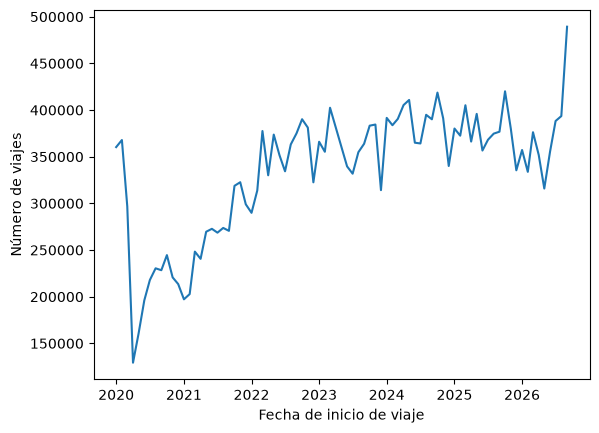

In [92]:
groupedby = df.groupby(redondear_a_primer_dia_del_mes(df["inicio_del_viaje"]))['viaje_id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

Se calcula el número de valores nulos:

In [93]:
# Solo Genero y Año de nacimiento tienen nulls
df.isna().sum()

viaje_id                   0
usuario_id                 0
genero                135232
anio_de_nacimiento     33796
inicio_del_viaje           0
fin_del_viaje              0
origen_id                  0
destino_id                 0
nombre_archivo             0
dtype: int64

Se analiza si existe correlación entre Género y Año de Nacimiento en cuanto a su distribución. La correlación obtenida es baja, y por lo tanto no existe correlación entre la distribución de nulos de ambas columnas.

In [94]:
# No hay correlacion entre los nulos de Genero y los nulos de año de nacimiento
null_matrix = df[["genero","anio_de_nacimiento"]].isnull().astype(int)
null_corr = null_matrix.corr(method='pearson')
null_corr

,genero,anio_de_nacimiento
genero,1.000000,0.058628
anio_de_nacimiento,0.058628,1.000000


In [95]:
# 26223500 records no tienen ninguna de estas columnas (Genero, Año de nacimiento) nulas
# 160780 tienen una u otra nula
# 4124 tienen ambas nulas
null_matrix.sum(axis=1).value_counts()

0    26223500
1      160780
2        4124
Name: count, dtype: int64

Se analiza el dataframe por tipo de dato:

In [96]:
cat_cols = df.select_dtypes(include=["str","object"]).columns.tolist()
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
time_cols = df.select_dtypes(include=["datetime"]).columns.tolist()
assert len(cat_cols) + len(num_cols) + len(time_cols) == len(df.columns)

Primero se analizan las categóricas:

In [97]:
cat_stats_df = df[cat_cols].describe().T
cat_stats_df

# El archivo 2026_09 es el que tiene más records

,count,unique,top,freq
genero,26253172,2,M,19130341
nombre_archivo,26388404,79,datos_abiertos_2026_09.parquet,489298


Se obtiene la distribución porcentual de género:

In [98]:
df["genero"].value_counts()*100/len(df)

genero
M    72.495256
F    26.992277
Name: count, dtype: float64

Ahora se analizan las numéricas:

In [99]:
num_stats_df = df[num_cols].describe().T
num_stats_df["kurt"] = df[num_cols].kurt()
num_stats_df["skew"] = df[num_cols].skew()
num_stats_df

# Año de nacimiento mínimo de 1 es inusual
# Año de nacimiento máximo de 2023 también

,count,mean,std,min,25%,50%,75%,max,kurt,skew
viaje_id,26388404.0,30578734.921686,9263286.459761,14420217.0,22414242.75,31019053.5,38646847.25,46255558.0,-1.234371,-0.039101
usuario_id,26388404.0,1495678.634557,1440525.197651,102.0,424402.0,767145.0,2265472.0,5006315.0,-0.140964,1.073652
anio_de_nacimiento,26354608.0,1989.057564,17.043189,1.0,1984.0,1992.0,1997.0,2023.0,7575.469387,-67.4458
origen_id,26388404.0,145.326156,105.668474,2.0,51.0,142.0,235.0,519.0,-0.919526,0.448159
destino_id,26388404.0,145.958889,107.948258,2.0,51.0,134.0,248.0,519.0,-0.974808,0.460595


Solo una de estas variables no es un id: año de nacimiento. Los IDs no ameritan un análisis numérico; se analizarán en otra sección revisando records repetidos para los viajes, y IDs no existentes en la tabla de estaciones para los IDs de origen y destino.

Los años de nacimiento inusuales se remueven:

In [100]:
# Se quitan los datos donde el año de nacimiento es menor a 1900
df = df[df["anio_de_nacimiento"] >= 1900]

In [101]:
# Solo hay 3 años de nacimiento distintos mayores a 2010
df[df["anio_de_nacimiento"] > 2010].anio_de_nacimiento.value_counts()

anio_de_nacimiento
2023    1151
2021     568
2022     374
Name: count, dtype: Int64

In [102]:
# Para evaluar estos registros se toma un approach diferente
# se estima la edad aproximada de la persona cuando ocurrió el viaje
df["edad_aproximada"] = df["inicio_del_viaje"].dt.year - df["anio_de_nacimiento"]

In [103]:
# Todos los que pudieran tener una edad de 5 años o menos, tienen entre 0 y 2 años
df[df["edad_aproximada"] < 6].edad_aproximada.value_counts()

edad_aproximada
1    1095
0     569
2     429
Name: count, dtype: Int64

In [104]:
# Por lo tanto, se interpretan como records erroneos y se eliminan
df = df[df["edad_aproximada"] > 5]

In [105]:
# La edad aproximada no es una variable deseada; se creó solo para este análisis
# Se descarta a continuación:
df = df.drop("edad_aproximada", axis=1)

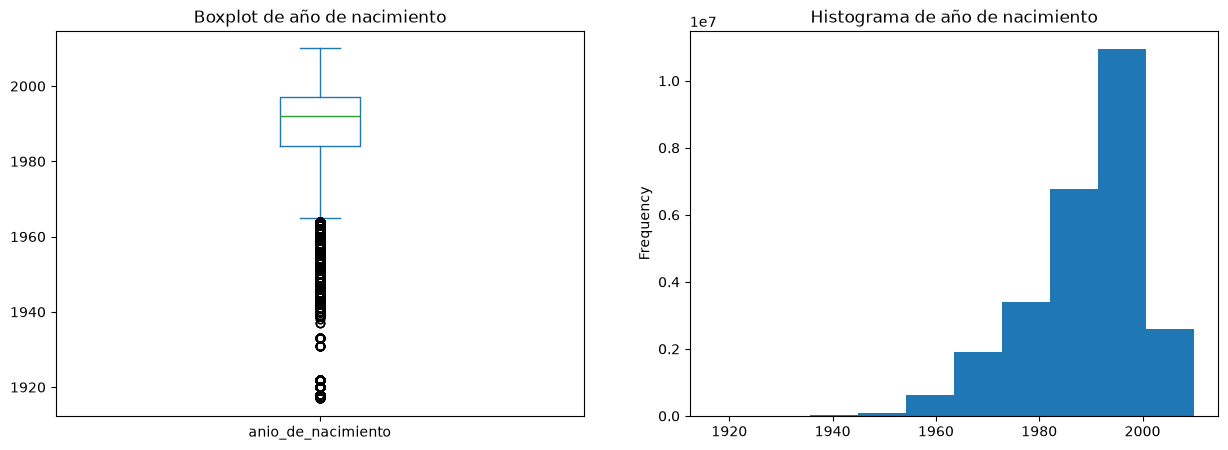

In [106]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
df.anio_de_nacimiento.plot.box()
plt.title("Boxplot de año de nacimiento")

plt.subplot(1,2,2)
df.anio_de_nacimiento.plot.hist()
plt.title("Histograma de año de nacimiento")

plt.show()

Este análisis se conserva para la posteridad, pero cabe destacar que para el problema P2 el año de nacimiento no es relevante.

Ahora se analizan los IDs. Primero los de viaje:

In [107]:
df["viaje_id"].value_counts().head(100)

viaje_id
14420217    1
14420218    1
14420219    1
14420220    1
14420221    1
           ..
14420327    1
14420328    1
14420329    1
14420330    1
14420333    1
Name: count, Length: 100, dtype: Int64

No existen IDs de viaje duplicados.

Ahora se limpian los IDs de origen y destino. Estos requieren analizar también los IDs de estaciones del archivo de nomenclaturas, y por lo tanto se carga primero:

In [108]:
estaciones_df = pd.read_csv(f"{DATA_DIR}/nomenclatura_estaciones.csv")

In [109]:
estaciones_df.head(10)

,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11
5,8,(GDL-006) C. Venustiano Carranza /C. Reforma,20.680717,-103.344415,11
6,9,(GDL-007) C. Epigmenio Glez./Av. Cristobal C.,20.666771,-103.350562,15
7,10,(GDL-008) C. Ignacio Zaragoza / C. J. Angulo,20.681953,-103.349992,15
8,11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23
9,12,(GDL-010) C. Cruz verde / C. Joaquin Angulo,20.681852,-103.357338,15


El problema a analizar requiere analizar la capacidad de cada estación. Por lo tanto, primero se descartan estaciones con capacidad de 0:

In [110]:
estaciones_df = estaciones_df[estaciones_df["dpcapacity"] > 0]

Ahora, en el dataframe de viajes, se descartan records con orígenes y destinos no presentes en el dataframe de estaciones:

In [111]:
# Si un id no está en el archivo de la nomenclatura, no es posible analizarlo para el problema P2. Los records con estos ids se eliminan
def descartar_records_con_id_inexistente_en_nomenclatura(datos_df, estaciones_df, col_origen, col_destino, col_id_nomenclatura):
    datos_df = datos_df.copy()
    origen_id_no_en_nomenclatura = ~(datos_df[col_origen].isin(estaciones_df[col_id_nomenclatura].unique()))
    destino_id_no_en_nomenclatura = ~(datos_df[col_destino].isin(estaciones_df[col_id_nomenclatura].unique()))
    return datos_df[~(origen_id_no_en_nomenclatura | destino_id_no_en_nomenclatura)]

In [112]:
df = descartar_records_con_id_inexistente_en_nomenclatura(df, estaciones_df, "origen_id", "destino_id", "id")

Finalmente, se analizan las columnas de tiempo.

In [113]:
df[time_cols].describe().T

,count,mean,min,25%,50%,75%,max
inicio_del_viaje,26347299,2023-09-01 09:56:38.225065,2020-01-01 06:02:20,2022-02-23 20:00:24.500000,2023-11-05 13:06:00,2025-04-11 08:36:11.500000,2026-09-30 23:59:48
fin_del_viaje,26347299,2023-09-01 10:07:38.567206,2020-01-01 06:05:38,2022-02-23 20:10:48.500000,2023-11-05 13:19:00,2025-04-11 08:46:16.500000,2026-10-01 00:14:52


Ambas variables tienen rangos esperados: primer viaje inició el 1 de enero del 2020, el último viaje inició el 30 de septiembre del 2026. Cabe destacar que algunos de los viajes que iniciaron el 30 de septiembre, concluyeron en las primeras horas del 1 de octubre del 2026. No se desea evaluar la capacidad de las estaciones más allá de septiembre 2026; por lo tanto, se filtran estos records:

In [114]:
# 16 records terminaron después de septiembre 2026
sum(df["fin_del_viaje"] >= '2026-10-01 00:00:00')

16

In [115]:
df = df[df["fin_del_viaje"] < '2026-10-01 00:00:00']

Como último punto a analizar respecto a columnas de tiempo, se evalua si existen registros con duraciones de tiempo no realistas.

In [116]:
df["duracion_del_viaje"] = (df.fin_del_viaje - df.inicio_del_viaje).dt.total_seconds()

In [117]:
df["duracion_del_viaje"].sort_values(ascending=False).head(10) / (60*60*24)

3292526     19.549144
108473      17.210660
4042178     16.863264
3897347     12.031111
2380157      9.731296
20999511     7.986644
1966431      7.584236
1979978      6.221910
3972143      5.378160
1980304      4.930231
Name: duracion_del_viaje, dtype: float64

In [119]:
df["duracion_del_viaje"].sort_values(ascending=True).head(10)

13319353    0.0
17471201    0.0
17471368    0.0
17471496    0.0
17471673    0.0
8783482     0.0
23922994    0.0
17471740    0.0
17471164    0.0
6130863     0.0
Name: duracion_del_viaje, dtype: float64

Algunos viajes muestran duraciones de tiempo inusuales. Los 10 registros más comunes muestran duraciones de alrededor de 5 días o más. El más extenso duró más de 19 días. Aunque no son realistas, no son imposibles y por lo tanto se conservan.

Cabe destacar que la duración mínima de viajes es de 0. Por lo tanto, no existen casos donde inicio_del_viaje > fin_del_viaje. Esto se puede validar: 

In [120]:
df[df["inicio_del_viaje"] > df["fin_del_viaje"]]

,viaje_id,usuario_id,genero,anio_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id,nombre_archivo,duracion_del_viaje


In [121]:
df = df.drop("duracion_del_viaje", axis=1)

## Preprocesamiento de datos

### Prueba: Obtener un conteo de entradas y salidas diarias por estación

In [135]:
def conteo_de_ids_por_fecha(df, col_fecha, col_id):
    resultado = (
        df.assign(fecha_a_agrupar=df[col_fecha].dt.date)
        .groupby(["fecha_a_agrupar", col_id])[col_id]
        .count()
        .reset_index(name="count")
        )
    return resultado

In [136]:
salidas_diarias = conteo_de_ids_por_fecha(df, "inicio_del_viaje", "origen_id")
entradas_diarias = conteo_de_ids_por_fecha(df, "fin_del_viaje", "destino_id")

In [ ]:
movimientos_df = (
    pd.merge(left=salidas_diarias,
         right=entradas_diarias,
         how="outer",
         left_on=["fecha_a_agrupar", "origen_id"],
         right_on=["fecha_a_agrupar", "destino_id"])
    .fillna(0)
)

movimientos_df["id"] = df["origen_id"].combine_first(df["destino_id"])
movimientos_df = (
    movimientos_df.rename(columns={"count_x": "salidas", "count_y": "entradas"})
                          .drop(["origen_id", "destino_id"], axis=1)
                          )
movimientos_df["diff"] = movimientos_df["entradas"] - movimientos_df["salidas"]
movimientos_df = pd.merge(movimientos_df, estaciones_df[["id","dpcapacity"]], how="left", on="id")
movimientos_df

,fecha_a_agrupar,salidas,entradas,id,diff
0,2020-01-01,10,9,52,-1
1,2020-01-01,11,5,254,-6
2,2020-01-01,6,7,258,1
3,2020-01-01,13,8,200,-5
4,2020-01-01,12,12,151,0
...,...,...,...,...,...
782884,2026-10-01,0,1,73,1
782885,2026-10-01,0,2,86,2
782886,2026-10-01,0,2,229,2
782887,2026-10-01,0,1,74,1


In [147]:
movimientos_df["diff"] = movimientos_df["dpcapacity"] + movimientos_df["diff"]
movimientos_df

,fecha_a_agrupar,salidas,entradas,id,diff,dpcapacity
0,2020-01-01,10,9,52,22.0,23.0
1,2020-01-01,11,5,254,9.0,15.0
2,2020-01-01,6,7,258,24.0,23.0
3,2020-01-01,13,8,200,10.0,15.0
4,2020-01-01,12,12,151,15.0,15.0
...,...,...,...,...,...,...
782884,2026-10-01,0,1,73,16.0,15.0
782885,2026-10-01,0,2,86,25.0,23.0
782886,2026-10-01,0,2,229,21.0,19.0
782887,2026-10-01,0,1,74,16.0,15.0


In [151]:
movimientos_df.describe().T

,count,mean,std,min,25%,50%,75%,max
salidas,782889.0,33.654908,33.639412,0.0,11.0,24.0,45.0,559.0
entradas,782889.0,33.654908,36.188535,0.0,10.0,24.0,45.0,566.0
id,781378.0,128.303607,91.060513,2.0,50.0,88.0,202.0,296.0
diff,781378.0,18.249836,10.983462,-152.0,12.0,17.0,23.0,227.0
dpcapacity,781378.0,18.249484,5.485534,11.0,15.0,15.0,23.0,39.0


In [153]:
movimientos_df[movimientos_df["diff"] == movimientos_df["diff"].min()]

,fecha_a_agrupar,salidas,entradas,id,diff,dpcapacity
5915,2020-01-22,248,81,160,-152.0,15.0


### Prueba: Conteo con ventana de tiempo

In [31]:
def obtener_dataframe_de_eventos(viajes_df, col_inicio_viaje="inicio_del_viaje", col_origen_id="origen_id", col_fin_de_viaje="fin_de_viaje", col_destino_id="destino_id"):
    salidas_df = pd.DataFrame({"tiempo": df["inicio_del_viaje"], "estacion": df["origen_id"], "delta": -1, "orden": 0})
    entradas_df = pd.DataFrame({"tiempo": df["fin_del_viaje"], "estacion": df["destino_id"], "delta": 1, "orden": 1})
    eventos_df = pd.concat([salidas_df, entradas_df], ignore_index=True)
    eventos_df = eventos_df.sort_values(["estacion", "tiempo", "orden"], kind="stable").reset_index(drop=True)
    eventos_df["cumsum"] = eventos_df.groupby("estacion")["delta"].cumsum()
    
    return eventos_df

ev_df = obtener_dataframe_de_eventos(df)

In [53]:
def bin_grid(ev, freq="15min", inicio=None, final=None):
    ev = ev.copy()
    ev["bin"] = ev["tiempo"].dt.floor(freq)
    g = ev.groupby(["estacion", "bin"]).agg(
        salidas=("delta", lambda x: int((x < 0).sum())),
        entradas=("delta", lambda x: int((x > 0).sum())),
        cumsum_fin=("cumsum", "last"), cumsum_min=("cumsum", "min"), cumsum_max=("cumsum", "max"))
    inicio = inicio or ev["bin"].min()
    final = final or ev["bin"].max()
    bins = pd.date_range(inicio, final, freq=freq)
    idx = pd.MultiIndex.from_product([sorted(ev["estacion"].unique()), bins], names=["estacion", "bin"])
    g = g.reindex(idx)
    g[["salidas", "entradas"]] = g[["salidas", "entradas"]].fillna(0).astype(int)
    g["cumsum_fin"] = g.groupby(level=0)["cumsum_fin"].ffill().fillna(0)
    prev = g.groupby(level=0)["cumsum_fin"].shift(1).fillna(0)   # nivel al inicio del bin
    g["cumsum_min"] = np.minimum(g["cumsum_min"].fillna(np.inf), prev).where(g["cumsum_min"].notna(), prev)
    g["cumsum_max"] = np.maximum(g["cumsum_max"].fillna(-np.inf), prev).where(g["cumsum_max"].notna(), prev)
    g["neto"] = g["entradas"] - g["salidas"]
    return g


In [48]:
ev_df.estacion.value_counts()

estacion
51     1247900
35      850558
271     786372
11      755991
50      709509
        ...   
510        388
509        374
514        309
465        281
511        215
Name: count, Length: 472, dtype: Int64

In [78]:
grid_df = bin_grid(ev_df[(ev_df["estacion"] >= 50) & (ev_df["estacion"] < 60)])

In [79]:
def l0_bounds(grid, cap):
    cmin = grid["cumsum_min"].groupby(level=0).min()
    cmax = grid["cumsum_max"].groupby(level=0).max()
    out = pd.DataFrame({"cap": cap.reindex(cmin.index), "lo": -cmin, "cmax": cmax})
    out["hi"] = out["cap"] - out["cmax"]
    out["rango_flujo"] = out["cmax"] - cmin
    out["factible"] = out["lo"] <= out["hi"]
    return out[["cap", "lo", "hi", "rango_flujo", "factible"]]

In [67]:
grid_df["neto"].groupby(level=0).max() - grid_df["neto"].groupby(level=0).min()

estacion
50    34
Name: neto, dtype: int32

In [ ]:
dpcapacity_series = estaciones_df.set_index("id")["dpcapacity"]

In [80]:
l0_bounds(grid_df, dpcapacity_series)

,cap,lo,hi,rango_flujo,factible
estacion,,,,,
50,23,64.0,-16316.0,16403.0,False
51,39,14.0,-145475.0,145528.0,False
52,23,5645.0,1.0,5667.0,False
53,15,3.0,-12464.0,12482.0,False
54,23,14.0,-24405.0,24442.0,False
55,15,9.0,-5572.0,5596.0,False
56,27,-0.0,-45388.0,45415.0,False
57,15,4.0,-9714.0,9733.0,False
58,19,13.0,-43561.0,43593.0,False


In [83]:
grid_df

salidas  entradas  cumsum_fin  cumsum_min  \
estacion bin                                                              
50       2020-01-01 06:00:00        1         0        -1.0        -1.0   
         2020-01-01 06:15:00        0         0        -1.0        -1.0   
         2020-01-01 06:30:00        0         0        -1.0        -1.0   
         2020-01-01 06:45:00        0         0        -1.0        -1.0   
         2020-01-01 07:00:00        1         0        -2.0        -2.0   
...                               ...       ...         ...         ...   
59       2026-09-30 22:45:00        0         0      6169.0      6169.0   
         2026-09-30 23:00:00        0         0      6169.0      6169.0   
         2026-09-30 23:15:00        0         0      6169.0      6169.0   
         2026-09-30 23:30:00        0         0      6169.0      6169.0   
         2026-09-30 23:45:00        0         0      6169.0      6169.0   

                              cumsum_max  neto  
estacion bin                                    
50       2020-01-01 06:00:00         0.0    -1  
         2020-01-01 06:15:00        -1.0     0  
         2020-01-01 06:30:00        -1.0     0  
         2020-01-01 06:45:00        -1.0     0  
         2020-01-01 07:00:00        -1.0    -1  
...                                  ...   ...  
59       2026-09-30 22:45:00      6169.0     0  
         2026-09-30 23:00:00      6169.0     0  
         2026-09-30 23:15:00      6169.0     0  
         2026-09-30 23:30:00      6169.0     0  
         2026-09-30 23:45:00      6169.0     0  

[2366160 rows x 6 columns]